## Implementing algorithm 1 from the paper. 
Computing omega points for the 3vs1 case
including the functions to check if points are in a good position 


In [22]:
import gudhi
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import matplotlib
from math import cos, sin, pi, atan
import itertools

import numpy.linalg

## for checking if in convex hull
import scipy.spatial
from scipy.optimize import linprog

import sys 
sys.path.append('../Code/')
import modules as mod
import examples as ex
import plot as ourplot
import csv

import omega_pts as omega
# This reloads external modules every time a cell is run
# so we don't have to reboot kernel every time we modify classes.py
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Note to selves: both 2:2 and 3:1 still need that we remove omega pts if they are already crit pts

Also note to self: needed to say CritPts[a].coords instead of CritPts[a] here for checking 4 distinct to actually work. Should we update elsewhere? check.

## Examples from the paper

### Example 2.13, figure 3

$M = [0,7)\times [0,8) \cup [0,7)\times [4,11)$ and $N = [0,7)\times [0,11) \cup [0,7)\times [4,8)$

**********
Computed 1848 points (with duplicates)
Without duplicates 60


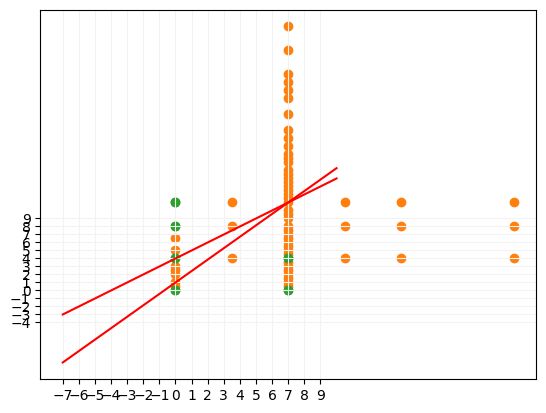

In [25]:
CritPts = ex.example_2_13()
name = "2_13"
Pts = omega.output_alg_3_1(CritPts, name)
ourplot.plotmod(CritPts, Pts)

### Example 2.11

$M = [0,7)\times [0,7) \cup [0,7)\times [4,11)$ and $N = [0,7)\times [0,11) \cup [0,7)\times [4,7)$

**********
Computed 1852 points (with duplicates)
Without duplicates 55


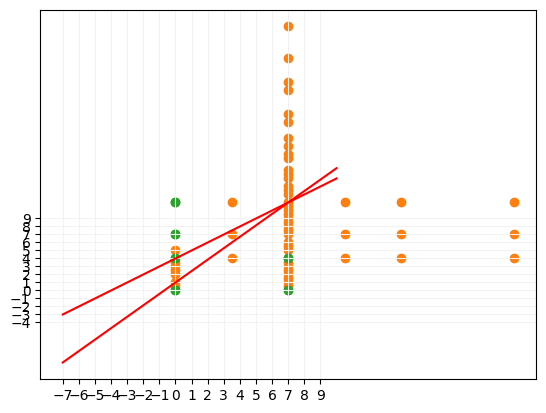

In [29]:
CritPts = ex.example_2_11()
name = "2_11"
Pts = omega.output_alg_3_1(CritPts, name)
ourplot.plotmod(CritPts, Pts)

### Example 1
$M=[0,7]\times[0,8]$ and $N=[1,8]\times[1,9]$

**********
Computed 132 points (with duplicates)
Without duplicates 39


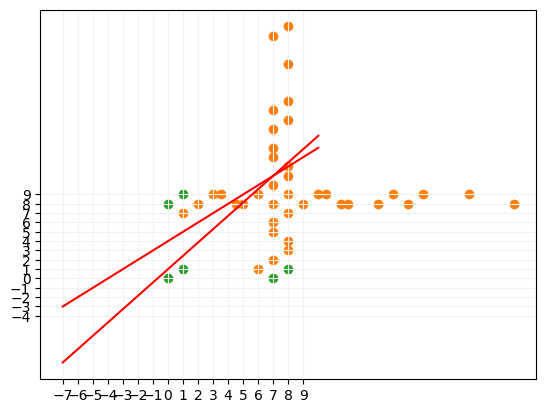

In [27]:
CritPts = ex.example_1()
name = "1"
Pts = omega.output_alg_3_1(CritPts, name)
ourplot.plotmod(CritPts, Pts)

### Example 2 
$M=[0,4]\times[0,4]$ and $N=[1,3]\times[0,4]$

Should have $(1,1),(2,2),(3,3)$ as $\Omega$-pts

**********
Computed 92 points (with duplicates)
Without duplicates 18


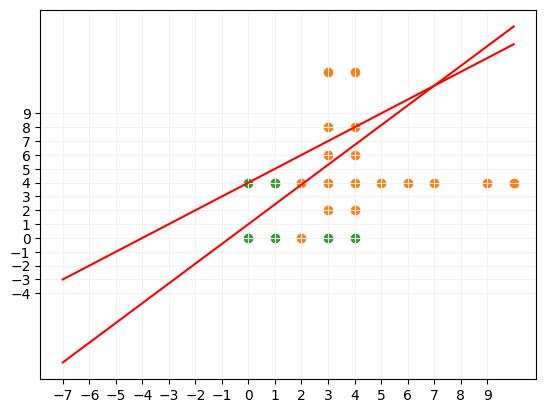

In [28]:
CritPts = ex.example_2()
name = "2"
Pts = omega.output_alg_3_1(CritPts, name)
ourplot.plotmod(CritPts, Pts)


###### remark: in this example we should not need the omega pts on the boundary of the support 

### without the closure 
in the examples above we ran the algorithm on $\overline{C_M}\sqcup\overline{C_N}$, here we try the last example above with $C_M\sqcup C_N$

In [34]:
c1 = mod.critical_val((0,0), 0)
c2 = mod.critical_val((4,0), 0)
c3 = mod.critical_val((0,4),0)

d1 = mod.critical_val((1,0), 1)
d2 = mod.critical_val((3,0), 1)
d3 = mod.critical_val((1,4),1)

CritPts = [c1,c2,c3,d1,d2,d3]

In [35]:
Pts =[]

for a in range(len(CritPts)): 
    for b in range(a+1,len(CritPts)):
        for c in range(b+1,len(CritPts)):
            for d in range(c, len(CritPts)):
                if omega.check_3distinct([CritPts[a],CritPts[b],CritPts[c],CritPts[d]]):
                    pts = omega.algo_3vs1([CritPts[a],CritPts[b],CritPts[c],CritPts[d]])
                    Pts +=pts
print('**********')
print("Computed {} points (with duplicates)".format(len(Pts)))

Pts = list(set(Pts))
print("Without duplicates {}".format(len(Pts)))

The omega point (4, 8.0) was generated from
x = (parent module of (4, 0) is 0)
w = (parent module of (0, 4) is 0)
u = (parent module of (0, 4) is 0)
v = (parent module of (0, 0) is 0)
****************
The omega point (4, 8.0) was generated from
x = (parent module of (4, 0) is 0)
w = (parent module of (0, 4) is 0)
u = (parent module of (0, 4) is 0)
v = (parent module of (0, 0) is 0)
****************
Computed 2 omega points with duplicates
Without duplicates: 2
The omega point (4, 8.0) was generated from
x = (parent module of (4, 0) is 0)
w = (parent module of (0, 0) is 0)
u = (parent module of (0, 4) is 0)
v = (parent module of (1, 0) is 1)
****************
The omega point (4, 4.0) was generated from
x = (parent module of (4, 0) is 0)
w = (parent module of (0, 4) is 0)
u = (parent module of (1, 0) is 1)
v = (parent module of (0, 0) is 0)
****************
The omega point (4, 2.0) was generated from
x = (parent module of (4, 0) is 0)
w = (parent module of (1, 0) is 1)
u = (parent module o

TypeError: unhashable type: 'list'

In [ ]:
fig = plt.figure(figsize=(10,6))
ax = fig.gca()

for pt in Pts:
    matplotlib.pyplot.scatter(pt[0], pt[1],c='C1')
for crit in CritPts:
    matplotlib.pyplot.scatter(crit.coords[0], crit.coords[1],c='C2', marker = "x", s=70)
    
ax.set_xticks(numpy.arange(-7,10, 1))
ax.set_yticks(numpy.arange(-4, 10, 1))

plt.grid(axis='both', color='0.95')

## NOtes meetin June 22
- check the code
- in example 1 we should not have (7,2) via check_omega BUT we should have (7,0), in particular the file should not be empty 

## Notes meeting June 08: 
### Todo: 
- discard $\omega$-pts that are in the closure of critical points 


## Todo: 
- print out vaalue of eta and delta when printing the omegapts and the critical points it comes from
- add something to know when it was computed in terms of line of code

## Further analysis: 
    2. Can we determine which ones are usless
    3. compute distance and see which $\Omega$-pts are interesting --> we also dont have ALL the $\Omega$-pts because we only implemented one part of the entire algo to compute the 3vs1 case and not the 2v2 cases

### IDEA: 

    omega-pts are center of symetries for bars hence they need to be in the support of the module 